# Exploratory Data Analysis: MLB Player Data

This notebook explores relationships between player demographics, career performance and salary using data cleaning, visualisation, hypothesis testing and OLS regression.

**To run this notebook:** the accompanying `mlb.csv` file is included in this repository package. Keep it in the same folder as this notebook, then run the cells from top to bottom.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

# Save selected static charts for the GitHub README.
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

# Bokeh is used for the interactive regression diagnostic plots later in the notebook.
from bokeh.io import output_notebook
output_notebook()
from bokeh.plotting import figure, show

Loading BokehJS ...

In [2]:
# Load the dataset from the notebook folder.
# If you store it in a data/ subfolder, change the path to Path("data") / "mlb.csv".
file_path = Path("mlb.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "Could not find 'mlb.csv'. Place the dataset in the same folder as this notebook. "
        "If the dataset was supplied by your university, check whether you are allowed "
        "to redistribute it before uploading it to a public repository."
    )

mlb_file = pd.read_csv(file_path)
print(f"Data loaded successfully: {mlb_file.shape[0]:,} rows and {mlb_file.shape[1]:,} columns.")
display(mlb_file.head(3))

Data loaded successfully: 352 rows and 21 columns.


,salary,player_position,race,team_payroll,years_played,games_played,career_at_bats,career_runs,career_hits,career_doubles,career_triples,career_homeruns,career_runs_batted_in,career_batting_average,career_walks,career_strike_outs,career_stolen_bases,career_fielding_percent,white_percent_in_city,black_percent_in_city,hispanic_percent_in_city
0,3375000,shortstop,black,38407380,8,918,3333,407,863,156,38,73,342,259,137,582,133,968,70.27797,18.84423,10.8778
1,3100000,firstbase,white,38407380,5,751,2807,370,840,148,18,46,355,299,341,228,41,994,70.27797,18.84423,10.8778
2,2900000,thirdbase,white,38407380,8,1056,3337,405,816,143,18,107,421,245,306,653,15,971,70.27797,18.84423,10.8778


## Data Formatting & Cleaning

In [3]:
#Check to see if there are any duplicated entries that need to be removed

# first check the size of the csv file
mlb_file.shape

(352, 21)

In [4]:
mlb_file.drop_duplicates(inplace=True)

# check the size again
mlb_file.shape

(352, 21)

**Comment:**

The shape size did not change which indicates that there were no duplicates in the file.

#### Check to see if there is any missing data

In [5]:
mlb_file.isnull().sum()

salary                       0
player_position              0
race                         0
team_payroll                 0
years_played                 0
games_played                 0
career_at_bats               0
career_runs                  0
career_hits                  0
career_doubles               0
career_triples               0
career_homeruns              0
career_runs_batted_in        0
career_batting_average       0
career_walks                 0
career_strike_outs           0
career_stolen_bases          0
career_fielding_percent      0
white_percent_in_city       23
black_percent_in_city       23
hispanic_percent_in_city    23
dtype: int64

**Comment:**

There is 23 missing values in the following 3 categories;

1. "white_percent_in_city"
2. "black_percent_in_city"
3. "hispanic_percent_in_city"

In [6]:
# drop the rows that contained a NaN value by calling `dropna`

mlb_file["black_percent_in_city"].isnull().sum()
mlb_file.dropna(inplace=True, axis=0)
mlb_file.isnull().sum()

salary                      0
player_position             0
race                        0
team_payroll                0
years_played                0
games_played                0
career_at_bats              0
career_runs                 0
career_hits                 0
career_doubles              0
career_triples              0
career_homeruns             0
career_runs_batted_in       0
career_batting_average      0
career_walks                0
career_strike_outs          0
career_stolen_bases         0
career_fielding_percent     0
white_percent_in_city       0
black_percent_in_city       0
hispanic_percent_in_city    0
dtype: int64

**Comment:**

Now there is no longer any missing data

## Descriptive Statistics and Graphs

In [7]:
# Access the basic descriptive statistics on each column of the dataframe

mlb_file.describe()

,salary,team_payroll,years_played,games_played,career_at_bats,career_runs,career_hits,career_doubles,career_triples,career_homeruns,career_runs_batted_in,career_batting_average,career_walks,career_strike_outs,career_stolen_bases,career_fielding_percent,white_percent_in_city,black_percent_in_city,hispanic_percent_in_city
count,3.290000e+02,3.290000e+02,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000
mean,1.331796e+06,3.069907e+07,6.389058,654.528875,2179.237082,290.869301,587.717325,104.671733,16.592705,55.559271,267.592705,258.240122,215.337386,343.477204,64.358663,976.373860,72.638240,16.541950,10.819810
std,1.366453e+06,8.252828e+06,3.821553,533.174656,2001.897302,297.161230,569.715073,103.873054,21.235427,74.276533,283.905072,33.060460,229.603300,325.915680,113.029778,20.057008,15.249897,13.688558,9.402261
min,1.090000e+05,8.854000e+06,1.000000,7.000000,7.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,111.000000,0.000000,0.000000,0.000000,800.000000,20.296300,3.741786,0.540870
25%,2.750000e+05,2.455733e+07,3.000000,245.000000,647.000000,79.000000,168.000000,28.000000,3.000000,8.000000,66.000000,245.000000,55.000000,108.000000,5.000000,969.000000,67.668960,8.007545,1.962080
50%,6.900000e+05,3.413650e+07,6.000000,533.000000,1617.000000,195.000000,426.000000,70.000000,9.000000,26.000000,176.000000,259.000000,137.000000,239.000000,25.000000,981.000000,74.619650,14.453980,10.877800
75%,2.250000e+06,3.722658e+07,9.000000,931.000000,3071.000000,405.000000,817.000000,148.000000,23.000000,72.000000,363.000000,275.000000,306.000000,480.000000,74.000000,988.000000,82.948860,18.755630,16.330650
max,6.200000e+06,4.266817e+07,20.000000,2729.000000,10554.000000,1570.000000,3025.000000,634.000000,142.000000,432.000000,1710.000000,571.000000,1286.000000,1891.000000,1042.000000,1000.000000,94.696270,73.960030,31.037500


In [8]:
mlb_file.info()

<class 'pandas.core.frame.DataFrame'>
Index: 329 entries, 0 to 351
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   salary                    329 non-null    int64  
 1   player_position           329 non-null    object 
 2   race                      329 non-null    object 
 3   team_payroll              329 non-null    int64  
 4   years_played              329 non-null    int64  
 5   games_played              329 non-null    int64  
 6   career_at_bats            329 non-null    int64  
 7   career_runs               329 non-null    int64  
 8   career_hits               329 non-null    int64  
 9   career_doubles            329 non-null    int64  
 10  career_triples            329 non-null    int64  
 11  career_homeruns           329 non-null    int64  
 12  career_runs_batted_in     329 non-null    int64  
 13  career_batting_average    329 non-null    int64  
 14  career_walks   

**Comment:**

The 'Dtype' column identifies the type of data. For example, both "player_position" & "race" are labelled as 'object' which means that they are Categorical data.

## Histogram

<Axes: >

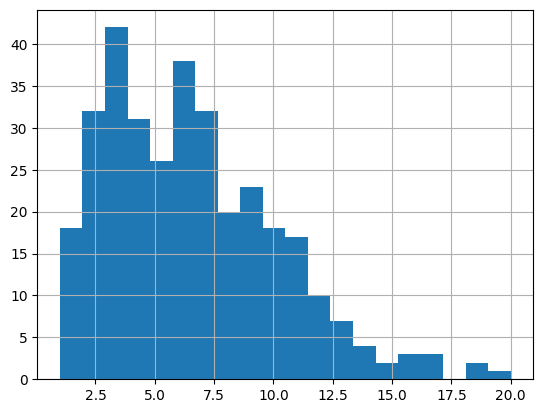

In [9]:
mlb_file["years_played"].hist(bins=20)

**Comment:**

Looking at the graph above, the distribution of the histogram is right-skewed. This indicates that the majority of players in the league have <u> less than 10 years played </u> in the league.

## Unique Values of a categorical data

In [10]:
# Identify the unique values for 'player positions'
mlb_file["player_position"].unique()

array(['shortstop', 'firstbase', 'thirdbase', 'outfield', 'catcher',
       'secondbase'], dtype=object)

In [11]:
# Identify the unique values for 'race'
mlb_file["race"].unique()

array(['black', 'white', 'hispanic'], dtype=object)

<Axes: title={'center': 'Over 50% of the MLB players are of white ethnicity'}, ylabel='Ethnicity'>

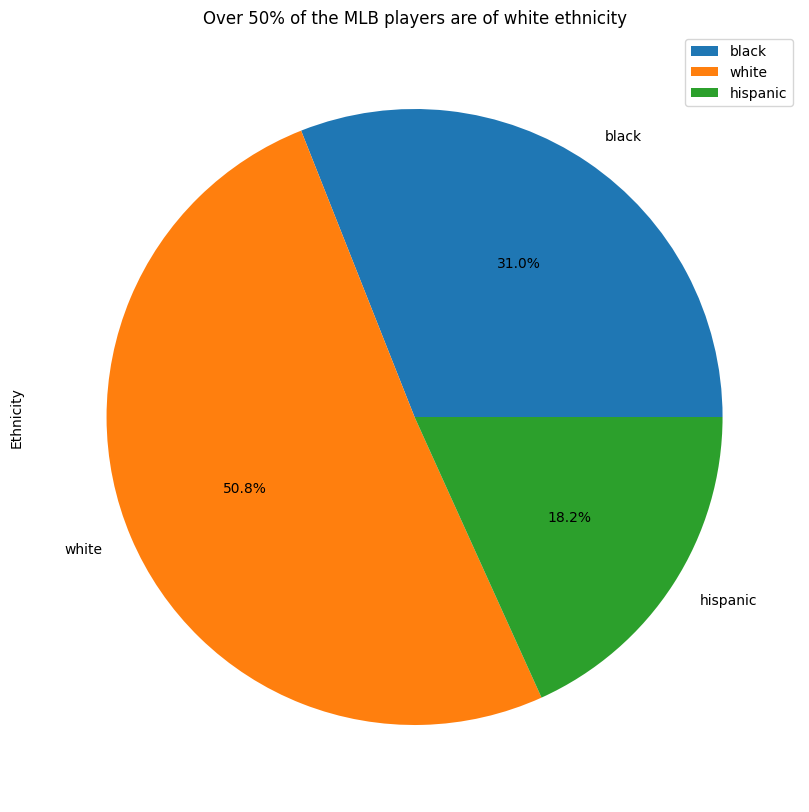

In [12]:
# Piechart for different ethnicities

race_counts = mlb_file['race'].value_counts()

race_df = pd.DataFrame({'Ethnicity': race_counts},
                     index = ['black', 'white', 'hispanic']
                   )
race_df.plot.pie(y='Ethnicity', figsize=(10,10), autopct='%1.1f%%',
                 title= "Over 50% of the MLB players are of white ethnicity")

## Contingency Table for Categorical data

In [13]:
cont_table = pd.crosstab(mlb_file['player_position'], mlb_file['race'])

# print the contingency table
cont_table

race,black,hispanic,white
player_position,,,
catcher,2,7,39
firstbase,10,8,24
outfield,69,19,40
secondbase,6,6,21
shortstop,7,17,21
thirdbase,8,3,22


**Comment:** From the table above we can identify that;

1. The population of black players are most represented in the outfield' position, and least represented in the 'catcher' position.

2. Looking at the white population of players, there is a more balanced distribution of of players in each position, compared to the other two population groups. Additionally, the large numbers of players in each population supports the observation made from the pie chart, that the majority of players in the league are of white ethnictity.

## Chi Square Test

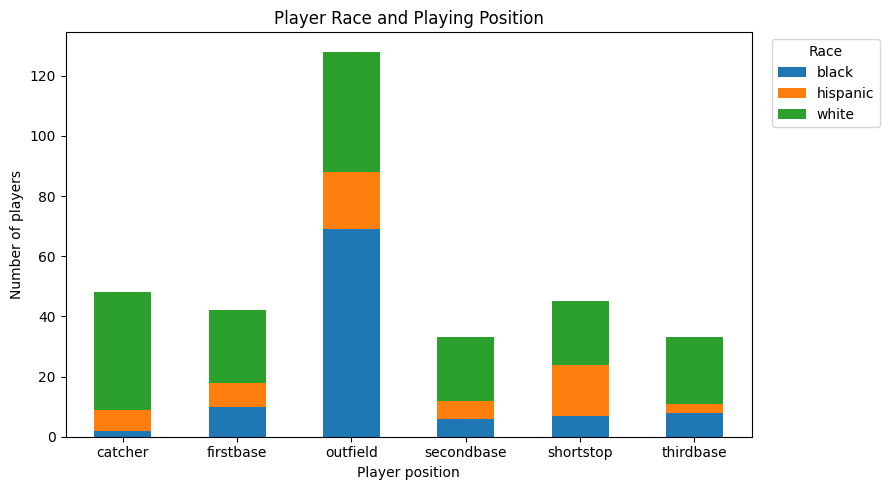

In [14]:
# Compare the distribution of player positions across race categories.
ax = cont_table.plot(
    kind="bar",
    stacked=True,
    rot=0,
    figsize=(9, 5),
    title="Player Race and Playing Position"
)
ax.set_xlabel("Player position")
ax.set_ylabel("Number of players")
ax.legend(title="Race", bbox_to_anchor=(1.02, 1), loc="upper left")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(IMAGE_DIR / "race_vs_position.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

**Comment:** The graph also shows that the outfield position is the most populated position

The **null hypothesis** of the chi-square test is *always* that <u> the two variables are independent </u> , the **alternative hypothesis** <u> is that they are dependent</u>.

The level of  **𝛼=0.05**  is a significance level commonly used in social sciences, so for this test <u> **we will set it to 0.05.**</u>

In [15]:
# run a chi-square test on the contingency table

chi2, p_val, dof, expected = stats.chi2_contingency(cont_table)
print(f"p-value: {p_val}")

p-value: 1.2087075896629676e-11


**Conclusion**:

The p-value is below the significance level (0.05), which suggests the null hypothesis should be rejected. Correspondingly, we can conclude that there is a dependence between the ethnicity group and the preference for a particular position.

Based on this finding, it suggests that when players enter the league, the position that they will play will likely to already be pre-determined by their race.

For example, a black player that enters the league is less likely to be in the 'catcher' position than a white player.

## Correlation between career homeruns and career walks

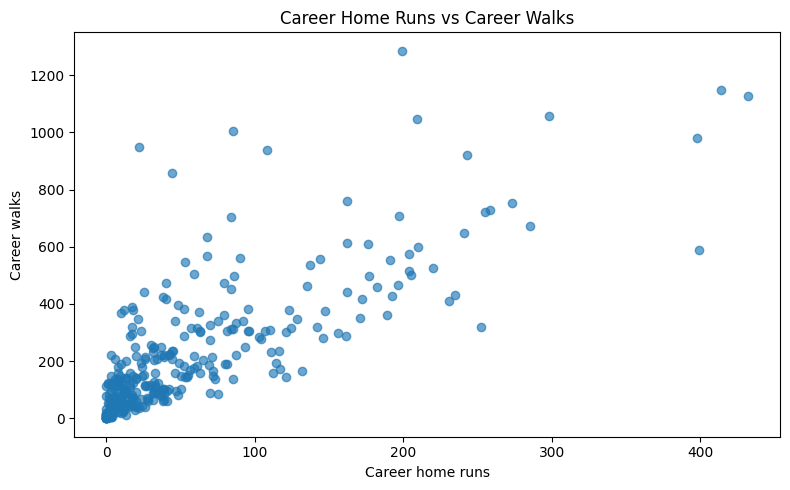

Spearman correlation coefficient: 0.819


In [16]:
# Explore the relationship between career home runs and career walks.
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(mlb_file["career_homeruns"], mlb_file["career_walks"], alpha=0.65)
ax.set_title("Career Home Runs vs Career Walks")
ax.set_xlabel("Career home runs")
ax.set_ylabel("Career walks")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "home_runs_vs_walks.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

correlate = mlb_file["career_homeruns"].corr(
    mlb_file["career_walks"], method="spearman"
)
print(f"Spearman correlation coefficient: {correlate:.3f}")

**Comment:**

From the results we can infer that there is a strong and postive relationship between **'career_homeruns'** and **'career_walks'.**

The spearman test has supported the scatter plot, as the spearman coefficient shows that the two variables have a strong and positive monotonic relationship.

It is important to note that correlation does not mean causality.

However, logically it makes sense as a player that has a lot of homeruns would be feared by the opposing team and therefore choose to let them walk as opposed to give them the chance to score a homerun against them.

## Hits Per Game Statistic

**Comment:**

Using NumPy arrays, the execution time of the code is <u> much</u> faster compared to using Python lists, meaning when deciding which alterntive implementation to use, the NumPy arrays code is the recommended choice.

In [17]:
# Create a function that will calculate the "hits per game" statistic, by using NumPy arrays.

# convert Python lists to NumPy arrays
np_career_hits = np.array(mlb_file['career_hits'])
np_games_played = np.array(mlb_file['games_played'])

np_hits_per_game = np_career_hits/np_games_played

In [18]:
# Use the 'timeit' function to calculate how long it takes for this code to complete.

%timeit np_hits_per_game = np_career_hits/np_games_played

1.39 μs ± 34.4 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


In [19]:
# add the array to the dataframe

mlb_file['hits_per_game'] = np_hits_per_game

In [20]:
mlb_file.head(3)

,salary,player_position,race,team_payroll,years_played,games_played,career_at_bats,career_runs,career_hits,career_doubles,career_triples,career_homeruns,career_runs_batted_in,career_batting_average,career_walks,career_strike_outs,career_stolen_bases,career_fielding_percent,white_percent_in_city,black_percent_in_city,hispanic_percent_in_city,hits_per_game
0,3375000,shortstop,black,38407380,8,918,3333,407,863,156,38,73,342,259,137,582,133,968,70.27797,18.84423,10.8778,0.940087
1,3100000,firstbase,white,38407380,5,751,2807,370,840,148,18,46,355,299,341,228,41,994,70.27797,18.84423,10.8778,1.118509
2,2900000,thirdbase,white,38407380,8,1056,3337,405,816,143,18,107,421,245,306,653,15,971,70.27797,18.84423,10.8778,0.772727


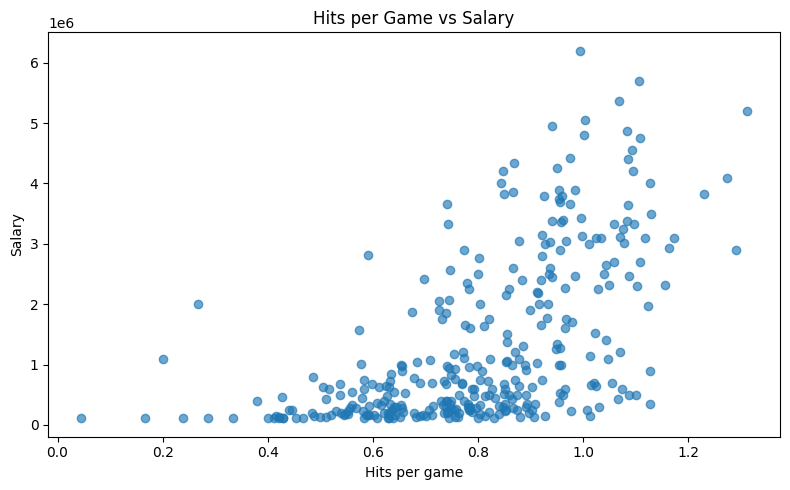

Spearman correlation coefficient: 0.634


In [21]:
# Explore the relationship between hits per game and salary.
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(mlb_file["hits_per_game"], mlb_file["salary"], alpha=0.65)
ax.set_title("Hits per Game vs Salary")
ax.set_xlabel("Hits per game")
ax.set_ylabel("Salary")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "hits_per_game_vs_salary.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

correlate = mlb_file["hits_per_game"].corr(
    mlb_file["salary"], method="spearman"
)
print(f"Spearman correlation coefficient: {correlate:.3f}")

**Comment:**

There is a moderately strong and positive monotonic relationship between these two variables.

## Creating Subsets

In [22]:
mlb_file.describe()

,salary,team_payroll,years_played,games_played,career_at_bats,career_runs,career_hits,career_doubles,career_triples,career_homeruns,career_runs_batted_in,career_batting_average,career_walks,career_strike_outs,career_stolen_bases,career_fielding_percent,white_percent_in_city,black_percent_in_city,hispanic_percent_in_city,hits_per_game
count,3.290000e+02,3.290000e+02,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000,329.000000
mean,1.331796e+06,3.069907e+07,6.389058,654.528875,2179.237082,290.869301,587.717325,104.671733,16.592705,55.559271,267.592705,258.240122,215.337386,343.477204,64.358663,976.373860,72.638240,16.541950,10.819810,0.801273
std,1.366453e+06,8.252828e+06,3.821553,533.174656,2001.897302,297.161230,569.715073,103.873054,21.235427,74.276533,283.905072,33.060460,229.603300,325.915680,113.029778,20.057008,15.249897,13.688558,9.402261,0.205121
min,1.090000e+05,8.854000e+06,1.000000,7.000000,7.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,111.000000,0.000000,0.000000,0.000000,800.000000,20.296300,3.741786,0.540870,0.045455
25%,2.750000e+05,2.455733e+07,3.000000,245.000000,647.000000,79.000000,168.000000,28.000000,3.000000,8.000000,66.000000,245.000000,55.000000,108.000000,5.000000,969.000000,67.668960,8.007545,1.962080,0.655928
50%,6.900000e+05,3.413650e+07,6.000000,533.000000,1617.000000,195.000000,426.000000,70.000000,9.000000,26.000000,176.000000,259.000000,137.000000,239.000000,25.000000,981.000000,74.619650,14.453980,10.877800,0.804598
75%,2.250000e+06,3.722658e+07,9.000000,931.000000,3071.000000,405.000000,817.000000,148.000000,23.000000,72.000000,363.000000,275.000000,306.000000,480.000000,74.000000,988.000000,82.948860,18.755630,16.330650,0.953890
max,6.200000e+06,4.266817e+07,20.000000,2729.000000,10554.000000,1570.000000,3025.000000,634.000000,142.000000,432.000000,1710.000000,571.000000,1286.000000,1891.000000,1042.000000,1000.000000,94.696270,73.960030,31.037500,1.311143


**Note:** I use the 25% row and the 75% row to identify the 25th perecentile and the 75th percentile, respectively.

In [23]:
# This subset retrieves all the players in the 75th percentile for hits_per_game & games_played

mlb_subset1 = mlb_file[(mlb_file.hits_per_game >= 0.953890) & (mlb_file.games_played >= 931.000000)]

# presenting descriptive statistics on the subset
mlb_subset1.describe()

,salary,team_payroll,years_played,games_played,career_at_bats,career_runs,career_hits,career_doubles,career_triples,career_homeruns,career_runs_batted_in,career_batting_average,career_walks,career_strike_outs,career_stolen_bases,career_fielding_percent,white_percent_in_city,black_percent_in_city,hispanic_percent_in_city,hits_per_game
count,4.500000e+01,4.500000e+01,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000
mean,2.952270e+06,3.308289e+07,11.933333,1568.088889,5870.533333,837.155556,1671.333333,294.288889,51.244444,168.288889,778.933333,283.733333,605.244444,804.866667,218.800000,978.533333,74.998490,15.231722,9.769788,1.061767
std,1.519351e+06,7.637652e+06,3.582787,499.283251,1902.058127,337.975117,564.754975,104.794956,32.231517,106.001634,330.303194,17.558215,278.651555,311.046591,218.641425,11.054822,12.144248,10.937332,8.394098,0.090872
min,2.250000e+05,8.854000e+06,7.000000,931.000000,3219.000000,79.000000,909.000000,124.000000,8.000000,18.000000,255.000000,259.000000,235.000000,291.000000,14.000000,952.000000,20.296300,3.741786,0.540870,0.954710
25%,1.975000e+06,2.739693e+07,9.000000,1106.000000,4145.000000,611.000000,1160.000000,222.000000,31.000000,86.000000,584.000000,270.000000,380.000000,584.000000,59.000000,971.000000,70.277970,9.049699,1.962080,0.994264
50%,3.100000e+06,3.571483e+07,11.000000,1475.000000,5669.000000,807.000000,1630.000000,273.000000,44.000000,162.000000,681.000000,284.000000,506.000000,736.000000,161.000000,979.000000,74.619650,13.871620,10.877800,1.048972
75%,3.897184e+06,3.855367e+07,14.000000,1844.000000,6879.000000,1067.000000,2000.000000,349.000000,62.000000,210.000000,913.000000,289.000000,759.000000,998.000000,262.000000,987.000000,83.115810,18.844230,14.802680,1.103163
max,6.200000e+06,4.266817e+07,20.000000,2729.000000,10554.000000,1570.000000,3025.000000,634.000000,142.000000,432.000000,1710.000000,338.000000,1286.000000,1733.000000,1042.000000,995.000000,94.696270,73.960030,31.037500,1.311143


In [24]:
### This subset retrieves all the players in the 75th percentile for hits_per_game
### but are only in the 25th percentile for games_played

mlb_subset2 = mlb_file[(mlb_file.hits_per_game >= 0.953890) & (mlb_file.games_played <= 533.000000)]

mlb_subset2.describe()

,salary,team_payroll,years_played,games_played,career_at_bats,career_runs,career_hits,career_doubles,career_triples,career_homeruns,career_runs_batted_in,career_batting_average,career_walks,career_strike_outs,career_stolen_bases,career_fielding_percent,white_percent_in_city,black_percent_in_city,hispanic_percent_in_city,hits_per_game
count,1.800000e+01,1.800000e+01,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000
mean,1.069454e+06,2.987697e+07,3.444444,356.833333,1295.833333,182.333333,365.333333,68.388889,8.500000,35.500000,178.000000,280.833333,127.833333,209.000000,32.055556,976.333333,77.008664,15.712006,7.279330,1.028283
std,8.665891e+05,8.947700e+06,1.381484,111.301525,376.522517,53.467967,113.497862,27.377833,4.617741,22.531677,72.197442,19.358081,68.151432,80.569298,26.233056,16.370706,10.007840,5.800251,6.985802,0.059591
min,1.500000e+05,1.558967e+07,1.000000,147.000000,579.000000,82.000000,149.000000,16.000000,3.000000,1.000000,42.000000,249.000000,55.000000,73.000000,4.000000,947.000000,51.496870,3.741786,0.540870,0.953890
25%,4.437500e+05,2.367997e+07,2.250000,324.250000,1178.750000,166.000000,331.000000,59.250000,6.000000,19.500000,142.250000,268.750000,79.000000,141.750000,13.000000,963.500000,70.995887,12.926868,1.922861,0.968855
50%,7.775000e+05,3.027567e+07,3.000000,362.500000,1306.500000,182.000000,362.000000,74.500000,7.000000,35.500000,207.000000,282.000000,107.500000,214.500000,20.000000,982.000000,79.472315,16.034660,3.317676,1.023263
75%,1.462500e+06,3.585774e+07,4.750000,436.000000,1565.000000,215.250000,455.000000,82.500000,9.500000,48.750000,232.250000,289.750000,146.500000,279.500000,52.500000,991.500000,82.722262,18.448812,12.453513,1.070405
max,3.110000e+06,4.266817e+07,6.000000,521.000000,1805.000000,295.000000,561.000000,122.000000,22.000000,75.000000,255.000000,322.000000,304.000000,344.000000,94.000000,995.000000,94.696270,30.953870,20.090960,1.127517


In [25]:
#calculating the average salary of both subsets

mlb_salary1 = mlb_subset1["salary"]
mlb_salary1.mean()

np.float64(2952270.1555555556)

In [26]:
mlb_salary2 = mlb_subset2["salary"]
mlb_salary2.mean()

np.float64(1069453.7222222222)

**Comment:**

'mlb_subset1' gathers the salary of players that are great hitters and have played a large amount of games.

Conversly, 'mlb_subset2' gathers the salary of players who are also great hitters, however they have played significantly less games.

Comparing the average salary of both subsets, the 'mlb_salary1' is <u> much</u> greater than 'mlb_salary2'.

In order to determine whether there is a significant difference between the means of the two populations from which the samples are drawn, we will need to run a **Independent Sample t-test**.

## Independent Sample t-test

The *Null* Hypothesis is that the difference between the two population means equals 0, i.e. there is no difference between them. The alternative hypothesis is that the mean of **mlb_subset2** is significantly lower or higher than the mean of **mlb_subset1**.

$H_0: \mu = 0$

$H_A: \mu \ne 0$

In [27]:
t_val, p_val = stats.ttest_ind(mlb_salary1, mlb_salary2)

print(f"t-value: {t_val}, p-value: {p_val}")

t-value: 4.931182278000137, p-value: 6.610358710101524e-06


**Conclusion:**

The p-value is smaller than the significance level ($\alpha=0.05$), i.e., the difference between the two means falls inside the rejection area.

Therefore we **reject the null hypothesis**.

Since the average salary of players in the mlb_subset1 is greater than those in the mlb_subset2 population, this implies that although teams value offensive talent i.e. how good of a hitter a player is, they also highly value experience. Meaning, they are much more likely to give a larger salary to a player that has the same level of offensive skill but has played a lot of games, compared to a younger and less proven player.

## Updating the dataframe with a Conditional Statement

In baseball, it is common to categorise how much experience a player has, based on the amount of years they have been in the league, by labelling them as either a "rookie", "sophmore", or "veteran".

In [28]:
def func(x):
    # the player is a "rookie" if they are in their first year
    if x['years_played'] <= 1:
        x['experience_tier'] = 'rookie'
    # the player is a "sophmore" if they are in their second year
    elif x['years_played'] == 2:
        x['experience_tier'] = 'sophmore'
    # the player is a "veteran" if they have 3 or more years played
    else:
        x['experience_tier'] = 'veteran'
    return x

# Use the "apply" function to create a new column that will correctly label each player based on their experience level.
mlb_file = mlb_file.apply(func, axis=1)

mlb_file

,salary,player_position,race,team_payroll,years_played,games_played,career_at_bats,career_runs,career_hits,career_doubles,career_triples,career_homeruns,career_runs_batted_in,career_batting_average,career_walks,career_strike_outs,career_stolen_bases,career_fielding_percent,white_percent_in_city,black_percent_in_city,hispanic_percent_in_city,hits_per_game,experience_tier
0,3375000,shortstop,black,38407380,8,918,3333,407,863,156,38,73,342,259,137,582,133,968,70.27797,18.84423,10.87780,0.940087,veteran
1,3100000,firstbase,white,38407380,5,751,2807,370,840,148,18,46,355,299,341,228,41,994,70.27797,18.84423,10.87780,1.118509,veteran
2,2900000,thirdbase,white,38407380,8,1056,3337,405,816,143,18,107,421,245,306,653,15,971,70.27797,18.84423,10.87780,0.772727,veteran
3,1650000,outfield,black,38407380,12,1196,3603,437,928,19,16,124,541,258,316,725,32,977,70.27797,18.84423,10.87780,0.775920,veteran
4,700000,outfield,black,38407380,17,2032,7489,1136,2145,270,142,40,574,286,416,1098,660,987,70.27797,18.84423,10.87780,1.055610,veteran
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347,312000,shortstop,white,35586456,5,439,1098,150,260,41,8,6,83,237,136,138,43,964,73.14964,13.87162,12.97875,0.592255,veteran
348,275000,catcher,hispanic,35586456,2,211,700,63,183,32,1,11,64,261,29,115,0,983,73.14964,13.87162,12.97875,0.867299,sophmore
349,250000,thirdbase,white,35586456,3,249,828,112,176,36,2,41,110,213,94,264,10,941,73.14964,13.87162,12.97875,0.706827,veteran
350,200000,secondbase,white,35586456,6,667,2087,217,510,92,5,13,168,244,137,239,20,987,73.14964,13.87162,12.97875,0.764618,veteran


## Grouping data

In [29]:
### Use the "groupby" method, to group all the observations by the 'experience_tier' and 'race'
### of all the players and present the mean.

mlb_file.groupby(['race', 'experience_tier']).mean(numeric_only=True)

salary  ...  hits_per_game
race     experience_tier                ...               
black    rookie           1.125000e+05  ...       0.620541
         sophmore         1.938889e+05  ...       0.775603
         veteran          1.820434e+06  ...       0.876815
hispanic rookie           1.130000e+05  ...       0.307962
         sophmore         4.371429e+05  ...       0.562438
         veteran          1.256435e+06  ...       0.810935
white    rookie           1.523000e+05  ...       0.678335
         sophmore         2.950938e+05  ...       0.694944
         veteran          1.441064e+06  ...       0.801886

[9 rows x 20 columns]

**Comment:**

There are a few common themes among the ethnic groups.

1. Firstly, for all races, as the players gain more experience (i.e. more games and more years played) the larger their salary becomes. Also their 'hits_per_game' also shares this trend, which alludes to the idea that as they spend more time in the league, the more they improve on their skills.


2. Looking at the 'veteran' subset, interestingly, Hispanics have relatively less games played than the other race groups (Black and White). This trend is also seen in the 'sophmore' subset, however the difference is not as large. This could indicate why the average salary for Hispanics, in all 3 exeperience tiers, is lower when comparing it to the average salary of the other two race groups.

## Multiple Linear Regression

Lets create a multiple linear regression model based on the certain independent variables. We are going to estimate this model using OLS:

$Salary = \alpha + \beta_1*TeamPayroll + \beta_2*HitsPerGame +\beta_3*CareerHomeruns +\beta_4*CareerRuns + \beta_5*GamesPlayed$

In [30]:
mlb_model = sm.OLS.from_formula(
    '''salary ~ team_payroll + hits_per_game
    + career_homeruns + career_runs + games_played''', data=mlb_file).fit()

In [31]:
mlb_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 salary   R-squared:                       0.503
Model:                            OLS   Adj. R-squared:                  0.495
Method:                 Least Squares   F-statistic:                     65.28
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           5.79e-47
Time:                        11:04:15   Log-Likelihood:                -4999.5
No. Observations:                 329   AIC:                         1.001e+04
Df Residuals:                     323   BIC:                         1.003e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       -1.192e+06   3.24e+05     -3.681      0.000   -1.83e+06   -5.55e+05
team_payroll        0.0169      0.007      2.541      0.012       0.004       0.030
hits_per_game    1.857e+06   3.42e+05      5.434      0.000    1.18e+06    2.53e+06
career_homeruns  5201.3883   1153.050      4.511      0.000    2932.952    7469.824
career_runs      1861.3780    557.346      3.340      0.001     764.891    2957.865
games_played     -477.6979    301.248     -1.586      0.114   -1070.353     114.957
==============================================================================
Omnibus:                       23.003   Durbin-Watson:                   1.395
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               27.795
Skew:                           0.578   Prob(JB):                     9.21e-07
Kurtosis:                       3.831   Cond. No.                     2.61e+08
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.61e+08. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

**Comment:**

Looking at the p-value of the independent variables, all are below the 0.05 significance level **except** for for the "games_played" variable. This means that while the other independent variables have a significant impact on a players salary, "games_played" is not significant and must therefore be removed from the model.

### New Model

$Salary = \alpha + \beta_1*TeamPayroll + \beta_2*HitsPerGame +\beta_3*CareerHomeruns +\beta_4*CareerRuns$

In [32]:
#create the new model and produce the summary statistics

mlb_model = sm.OLS.from_formula(
    '''salary ~ team_payroll + hits_per_game
    + career_homeruns + career_runs''', data=mlb_file).fit()

mlb_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 salary   R-squared:                       0.499
Model:                            OLS   Adj. R-squared:                  0.493
Method:                 Least Squares   F-statistic:                     80.60
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           2.09e-47
Time:                        11:04:15   Log-Likelihood:                -5000.7
No. Observations:                 329   AIC:                         1.001e+04
Df Residuals:                     324   BIC:                         1.003e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        -1.33e+06   3.13e+05     -4.253      0.000   -1.95e+06   -7.15e+05
team_payroll        0.0178      0.007      2.689      0.008       0.005       0.031
hits_per_game    1.903e+06   3.41e+05      5.577      0.000    1.23e+06    2.57e+06
career_homeruns  4680.8282   1107.912      4.225      0.000    2501.219    6860.437
career_runs      1131.8372    315.336      3.589      0.000     511.472    1752.202
==============================================================================
Omnibus:                       24.020   Durbin-Watson:                   1.369
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               30.183
Skew:                           0.578   Prob(JB):                     2.79e-07
Kurtosis:                       3.931   Cond. No.                     2.56e+08
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.56e+08. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

**Conclusion:**

(1) **Coefficients on the variables**. The estimated coefficients are specified in the second table. Our model is thus described by the line:

$Salary = -1,330,000 + 0.0178*TeamPayroll + 1,903,000*HitsPerGame + 4680.83*CareerHomeruns + 1131.84*CareerRuns + e$

In regards to the signs on the coefficients we can conclude that a player's salary is positively affected by the all the independent variables -- for instance, the greater the number of career homeruns a player has, the more likely the salary will also be higher. The only negative value is the intercept.

(2) **Significance of the variables**. The p-values signify that the variables are significant, meaning the factors have a statistically significant effect on the salary.

(3) **Quality of the model**. The adjusted $R^2$ value is below 0.5, which means that the quality of the model is not that good. The model only accounts for less than 50% of the factors that have an effect on the salary. This makes sense as we would expect that there are other unaccounted for determinants that will play a role in the value of a player's salary.

These could be;
1. Player's age
2. The quality of their agent
3. Length of contract
4. Whether they are a free agent or not
5. The player's marketability & brand name.

## Checking the assumptions of normality and zero mean of residuals

In [33]:
from bokeh.io import curdoc
# Clear the document to remove any lingering, broken glyph configurations
curdoc().clear()

resids_fig = figure(height=400, width=400)

# the x axis is the fitted values
# the y axis is the standardized residuals
st_resids = mlb_model.get_influence().resid_studentized_internal
resids_fig.scatter(mlb_model.fittedvalues, st_resids, marker="circle", size=8)

show(resids_fig)

**Comment:**

The residuals are randomly scattered around zero, and there is no apparent pattern to the residuals, which suggests that a linear model is appropriate for this relationship

In [34]:
#create histogram

hist, edges = np.histogram(st_resids, bins=10)

mlb_hist = figure(height=320, width=320)
mlb_hist.quad(top=hist, bottom=0, left=edges[:-1], right=edges[1:], line_color="white")
show(mlb_hist)

**Comment:**

The scatterplot and the histogram are used to test the validity of the model. They depicted that the residuals are equally distributed around 0 and are therefore normally distributed.

However, the results of the Jarque-Bera test on the residuals (the third table of the summary) indicate that the errors are **NOT** distributed normally: the p-value is much lower than the 0.05 significance level, ergo we should reject the null hypothesis of normal distribution.

Since the conclusions of the tests contradict each other, the suggestion would be to run more normality distribution tests, i.e., p-plot test.

## Using the model to predict a Player's salary

We will use the model that we have just created to try and predict the salary of a hypothetical player.

In [35]:
# Team Payroll = $437,142.90
# Hits per Game = 0.75
# Career Homeruns = 42
# Career Runs = 385

In [36]:
### There are several alternative methods to do this prediction,
### however the recommended choice is once again to use NumPy arrays for its efficiency compared to other methods

y = mlb_file['salary']
x = mlb_file[['team_payroll', 'hits_per_game', 'career_homeruns', 'career_runs']].values
x = sm.add_constant(x)
mlb_modelNPy = sm.OLS(y,x).fit()

In [37]:
mlb_modelNPy.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 salary   R-squared:                       0.499
Model:                            OLS   Adj. R-squared:                  0.493
Method:                 Least Squares   F-statistic:                     80.60
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           2.09e-47
Time:                        11:04:15   Log-Likelihood:                -5000.7
No. Observations:                 329   AIC:                         1.001e+04
Df Residuals:                     324   BIC:                         1.003e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -1.33e+06   3.13e+05     -4.253      0.000   -1.95e+06   -7.15e+05
x1             0.0178      0.007      2.689      0.008       0.005       0.031
x2          1.903e+06   3.41e+05      5.577      0.000    1.23e+06    2.57e+06
x3          4680.8282   1107.912      4.225      0.000    2501.219    6860.437
x4          1131.8372    315.336      3.589      0.000     511.472    1752.202
==============================================================================
Omnibus:                       24.020   Durbin-Watson:                   1.369
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               30.183
Skew:                           0.578   Prob(JB):                     2.79e-07
Kurtosis:                       3.931   Cond. No.                     2.56e+08
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.56e+08. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [38]:
#predict the model
mlb_pred = mlb_modelNPy.predict([[1, 437142.90, 0.75, 42, 385]])

mlb_pred[0]

np.float64(737181.4132930895)

In [39]:
# print the answer of predicted salary in a desired format
import math

predicted_salary = mlb_pred[0]
significant_digits = 8

# this code will round the answer to 2 decimal places
rounded_prediction =  round(predicted_salary, significant_digits - int(math.floor(math.log10(abs(predicted_salary)))) - 1)

print(f"The player's predicted salary is $ {rounded_prediction}")

The player's predicted salary is $ 737181.41


In [40]:
# this code below will calculate the average salary of all mlb players
mean_salary = mlb_file["salary"].mean()
significant_digits = 9

rounded_mean =  round(mean_salary, significant_digits - int(math.floor(math.log10(abs(mean_salary)))) - 1)

print(f"The average player's salary is $ {rounded_mean}")

The average player's salary is $ 1331796.12


**Comment:**

The predicted salary is a lot less than the average salary of a player in the mlb. However , it is important to note that because the adjusted $R^2$ value is so low (0.493) the model prediction is not likely to be accurate

# OVERALL CONCLUSIONS

1. Based on the **Chi-square test** we have determined that there is a **stastically significant relationship** between a players **race** and their **position**.

2. Futhermore, the **pie chart** that categorised player's by their **ethnicity** showed that **over 50%** of the league is of **"white"** ethnicity, while for **"black"** and **"hispanic"** players it was **31%** and **18.2%** respectively.

3. We found that there is a **strong** and **positive monotonic correlation** between **'career_homeruns'** & **'career_walks'**.

4. After creating two <u>subsets</u> and running an **independet sample T-test,** we found that **statistically significant** evidence that players with **less games played** are more likely to have a **lower salary** than players with **a lot more games played** in comparison. This is even if both players have the same offensive talent.

5. Interestingly, when the **'games_played'** variable was added to the <u>regression model</u>, we found that it did **NOT** have a *statistically significant* effect on the 'salary' and therefore had to be **removed** from the model. Which contradicts the finding that was made in point 4. This highights that correlation does not always mean causality.

6. It is important to note that because of the **low** adjusted $R^2$ value, the regression model is **NOT** likely to be **accurate** at predicting a players salary, as there are a multitude of other determinants that can affect a players salary that were not included in this dataset.

## Reproducing the analysis and chart exports

Run the notebook from top to bottom. The selected Matplotlib charts are saved as PNG files in the `images/` folder for use in the repository README. The three exported charts are:

- `images/race_vs_position.png`
- `images/home_runs_vs_walks.png`
- `images/hits_per_game_vs_salary.png`

The Bokeh residual diagnostic charts are interactive notebook outputs and are not exported as static images by this workflow. The accompanying `mlb.csv` file is included in this repository and must remain in the same directory as the notebook to rerun the analysis.